# Predicting Farinograph traits from GlutoPeak output — published random forest models applied to one sample

**Paper:** Price et al., *Random forest regression to predict Farinograph traits from GlutoPeak output in wheat wild relative backcross lines*, **Cereal Chemistry 102(3):466–476 (2025)**, [doi:10.1002/cche.10860](https://doi.org/10.1002/cche.10860)

**Author code:** [jhprice/Predicting_Farino_from_GP_RF](https://github.com/jhprice/Predicting_Farino_from_GP_RF) @ commit `e3e3894745242e6efc043bdfd7e3156a4fba5652` ("Code from publication")
**Data:** [Ag Data Commons / Figshare article 26487862](https://doi.org/10.15482/USDA.ADC/26487862) (CC0), 100 raw GlutoPeak `.xlsx` files.
**Weights:** `Random_forest_models_Glutopeak_farinograph.RData` + `Random_forest_modelsno_protein_Glutopeak_farinograph.RData` from the pinned repository (the paper's trained random forest models).

**Scope of this notebook (partial demonstration, one example):**
- Apply the **published, trained no-protein random forest models** to **one** raw GlutoPeak run file, following the author's `Apply prediction models.R` feature computation, and report predicted Farinograph traits.
- **Not** in scope: retraining models, dataset-wide evaluation, or reproduction of the paper's published accuracies (regression R² 0.488–0.745 across traits).

**Execution status:** this notebook is executed end-to-end on a fresh Colab CPU runtime; all outputs below are from that run.

> **AI-assisted adaptation notice (EN/JP):** The scientific feature computation and prediction run inside **the authors' pinned R code** (`Rscript`); the surrounding Python launcher/glue cells are AI-generated. The authors did not provide this Colab notebook. The executed example and listed checks were validated, but untested behavior is not guaranteed.
> **AI支援の注記:** 科学的な特徴量計算と予測は著者のRコード(Rscript)で実行します。周辺のPythonランチャー細工はAI生成です。著者自身はこのColabノートブックを提供していません。実行例と検証項目は確認済みですが、未検証の挙動は保証されません。

**日本語要約:** このノートブックは、著者が公開した学習済みランダムフォレストモデル(タンパク質情報なし版)を、GlutoPeakの生データ1ファイルに適用し、ファリノグラフ特性を予測します。特徴量計算は著者のRスクリプトをそのまま使用します。

## Runtime: **CPU only** — select *Runtime → Change runtime type → CPU*

The workload is a single 14 KB spreadsheet, 1.1 MB model files, and random forest **inference** in R. No GPU code path exists in the author's code, so a GPU adds nothing. Expected wall time on a fresh runtime: **~5–10 minutes** total (R package install dominates). Downloads: < 10 MB.

**Run all:** `Runtime → Run all`. No Drive mount, no credentials, no interactive prompts are required.

**日本語:** 実行環境はCPUのみで十分です(GPU不要)。`ランタイム → すべてのセルを実行` で動作します。所要時間は約5〜10分、ダウンロードは10MB未満です。

### 3.1 Check the R interpreter

The standard Colab CPU image ships `/usr/bin/Rscript` alongside Python. This launcher approach (Python kernelspec + `Rscript`) is used because the installed `colab` CLI cannot be assumed to execute a native R-kernel notebook; the same route was verified in a prior probe (2026-09-29, `R_SUM=6`). We first confirm the R interpreter and its version.

**日本語:** まずPythonカーネルから `Rscript` が使えるか確認します。これは以前のプローブで検証済みの経路です。

In [ ]:
import shutil, subprocess, sys

rscript = shutil.which("Rscript")
assert rscript, "/usr/bin/Rscript not found; use a Colab runtime image that includes R."
ver = subprocess.run([rscript, "--version"], capture_output=True, text=True, check=True)
print(ver.stderr.strip())
print("Python:", sys.version.split()[0])


Python: 3.13.16


### 3.2 Install the R packages the author's script loads

`Apply prediction models.R` loads: `tidyverse`, `slider`, `readxl`, `lubridate`, `data.table`. `randomForest` is required to work with the saved models and `caret` is required because the published `.RData` objects are **caret `train` objects** (verified in the diagnostic run: `predict()` fails without the caret namespace). We install the prebuilt Ubuntu packages (`r-cran-*`, fastest on Colab) and verify from R itself; any package the apt archive lacks is installed from CRAN. This cell is AI-generated glue around the author's `library()` calls — the package list is taken from the pinned script plus that verified requirement.

**日本語:** 著者のRスクリプトが必要とするパッケージに加え、保存済みモデルがcaretのtrainオブジェクトであるため `caret` も導入します。足りないものだけCRANから入れます。

In [ ]:
import subprocess

APT_PKGS = ["r-cran-tidyverse", "r-cran-slider", "r-cran-readxl",
            "r-cran-lubridate", "r-cran-data.table", "r-cran-randomforest",
            "r-cran-caret"]
subprocess.run(["bash", "-c",
                "DEBIAN_FRONTEND=noninteractive apt-get update -qq && "
                "DEBIAN_FRONTEND=noninteractive apt-get install -y " + " ".join(APT_PKGS)],
               check=True, timeout=1800)

NEEDED = ["tidyverse", "slider", "readxl", "lubridate", "data.table", "randomForest", "caret"]
check = subprocess.run(
    ["Rscript", "-e",
     'ip <- rownames(installed.packages()); cat(paste(intersect(c("' + '", "'.join(NEEDED) + '"), ip), collapse=" "))'],
    capture_output=True, text=True, check=True)
have = set(check.stdout.split())
print("already available:", sorted(have))
missing = sorted(set(NEEDED) - have)
if missing:
    print("installing from CRAN:", missing)
    expr = 'install.packages(c("' + '", "'.join(missing) + '"), repos="https://cloud.r-project.org", Ncpus=2)'
    subprocess.run(["Rscript", "-e", expr], check=True, timeout=1800)
else:
    print("all required R packages present")

already available: ['caret', 'data.table', 'lubridate', 'randomForest', 'readxl', 'slider', 'tidyverse']
all required R packages present


### 4.1 Download the pinned trained model files (weights) — Colab only

The two `.RData` files are the paper's trained random forest models, fetched from the **pinned commit** `e3e3894` of the author repository. Both are loaded by the author's apply script (lines 8–9). We verify the byte size and the **git blob SHA-1** of each download against the values recorded from the GitHub tree API (blob `3d8648f8…` 1,146,290 B and blob `8265e6a5…` 1,159,396 B), so a truncated or substituted payload fails loudly.

**日本語:** 論文の学習済みモデル(.RData)2ファイルをピン留めしたコミットから取得し、サイズとgit blobハッシュで検証します。

In [ ]:
import hashlib, pathlib, urllib.request

pathlib.Path("/content/gp_rf").mkdir(parents=True, exist_ok=True)
PINNED = "https://raw.githubusercontent.com/jhprice/Predicting_Farino_from_GP_RF/e3e3894745242e6efc043bdfd7e3156a4fba5652/Code%20from%20publication/"
WEIGHTS = [  # (filename, expected size in bytes, expected git blob sha1)
    ("Random_forest_models_Glutopeak_farinograph.RData", 1146290,
     "3d8648f88d59d78963e9b1b516fa7365dc31d415"),
    ("Random_forest_modelsno_protein_Glutopeak_farinograph.RData", 1159396,
     "8265e6a5aa2edcdc5338074a9e3ec14143cbfefe"),
]
for name, size, blob_sha in WEIGHTS:
    dest = "/content/gp_rf/" + name
    urllib.request.urlretrieve(PINNED + name, dest)
    payload = open(dest, "rb").read()
    got = hashlib.sha1(b"blob %d\x00" % len(payload) + payload).hexdigest()
    assert len(payload) == size, f"{name}: size {len(payload)} != {size}"
    assert got == blob_sha, f"{name}: blob sha {got} != {blob_sha}"
    print(f"OK {name}: {len(payload)} bytes, blob sha verified")

OK Random_forest_models_Glutopeak_farinograph.RData: 1146290 bytes, blob sha verified
OK Random_forest_modelsno_protein_Glutopeak_farinograph.RData: 1159396 bytes, blob sha verified


### 4.2 Download one raw GlutoPeak sample from the CC0 dataset — Colab only

The dataset (Ag Data Commons DOI `10.15482/USDA.ADC/26487862`, **CC0**) stores one Brabender GlutoPeak `.xlsx` per run; the paper used one run per sample (`Model development.R:88–95` also documents that `_long` files are runs originally longer than 150 s). We pick a standard (non-`_long`) run deterministically: **`230117006-004_44.xlsx`** (Figshare file id 48147478). The cell queries the official Figshare record API for the file metadata, downloads it, and verifies name/size/ZIP signature (`.xlsx` is a ZIP container). No learner login or token is needed.

**日本語:** CC0ライセンスのデータセットから、標準長(150秒以下)の生GlutoPeakファイルを1つ決定的に選んで取得・検証します。

In [ ]:
import json, pathlib, time, urllib.request

pathlib.Path("/content/gp_rf/sample").mkdir(parents=True, exist_ok=True)
ARTICLE = "https://api.figshare.com/v2/articles/26487862"
with urllib.request.urlopen(ARTICLE, timeout=60) as r:
    rec = json.load(r)
print("record:", rec["title"][:80], "| doi:", rec["doi"], "| license:", rec["license"]["name"])

FILE_ID, FILE_NAME, FILE_SIZE = 48147478, "230117006-004_44.xlsx", 14318
entry = next(f for f in rec["files"] if f["id"] == FILE_ID)
assert entry["name"] == FILE_NAME and entry["size"] == FILE_SIZE, entry
dest = "/content/gp_rf/sample/" + FILE_NAME
# ndownloader.figshare.com rejects urllib's default User-Agent with 403 on some
# edges; send an identifying client header and retry a bounded two times.
req = urllib.request.Request(entry["download_url"],
                             headers={"User-Agent": "phenopaper-colab-repro/1.0 (github.com/phytometrics)"})
payload = None
for attempt in range(3):
    try:
        with urllib.request.urlopen(req, timeout=120) as r2:
            payload = r2.read()
        break
    except urllib.error.HTTPError as e:
        print(f"download attempt {attempt + 1} failed: HTTP {e.code}")
        if attempt == 2:
            raise
        time.sleep(5 * (attempt + 1))
open(dest, "wb").write(payload)
assert payload[:2] == b"PK", "not a valid xlsx (ZIP) container"
assert len(payload) == FILE_SIZE, (len(payload), FILE_SIZE)
print(f"OK {FILE_NAME}: {len(payload)} bytes")

record: Data from: Random forest regression to predict Farinograph traits from GlutoPeak | doi: 10.15482/USDA.ADC/26487862.v1 | license: CC0


OK 230117006-004_44.xlsx: 14318 bytes


### 4.3 Inspect the raw input schema (in Colab, before running author code)

The author's script expects the Brabender sheet **`Measurement`** with columns ``Time[mm:ss]`` and ``TorqueMean[BU]`` (plus ``Torque[BU]`` used for the trapezoid areas). Before running the pinned R feature code, we look at the actual columns and `Time[mm:ss]` values so the subsequent `ymd_hms()` time conversion is applied to a verified format — the notebook must never hard-code an unverified schema.

**日本語:** 著者コードを実行する前に、`Measurement` シートの実際の列名と時刻形式をColab上で確認します。

In [ ]:
import openpyxl

XLSX = "/content/gp_rf/sample/230117006-004_44.xlsx"
wb = openpyxl.load_workbook(XLSX, read_only=True, data_only=True)
print("sheets:", wb.sheetnames)
ws = wb["Measurement"]
for row in ws.iter_rows(min_row=1, max_row=6, values_only=True):
    print(row)

sheets: ['Parameter', 'Measurement', 'Evaluation']
('Time[mm:ss]', 'Torque[BU]', 'TorqueMean[BU]', 'Speed[1/min]')
(datetime.timedelta(0), 0, 0, -32)
(datetime.timedelta(seconds=2), 0, 0, 0)
(datetime.timedelta(seconds=3), 0.002, 0.001, 49)
(datetime.timedelta(seconds=4), 0, 1.997, 164)
(datetime.timedelta(seconds=5), 6.544, 5.71, 298)


### 4.4 Preview the input: raw GlutoPeak torque curve

The minimal scientific input of this paper is one torque-vs-time curve (Brabender units, BU). This plot shows the actual downloaded sample's `TorqueMean[BU]` over the first 150 s — the curve whose summary statistics the paper feeds to its random forest models. The x-axis uses the author's own time convention (`minute*60 + second` from the `Time[mm:ss]` column, which matches elapsed seconds when the hour part is 0). (Figure created for this notebook from the actual sample, not an author figure.)

**日本語:** ダウンロードしたサンプルの生トルク曲線(0–150秒)を表示します。以降の特徴量計算の入力です。

points: 150, time span 0..150 s


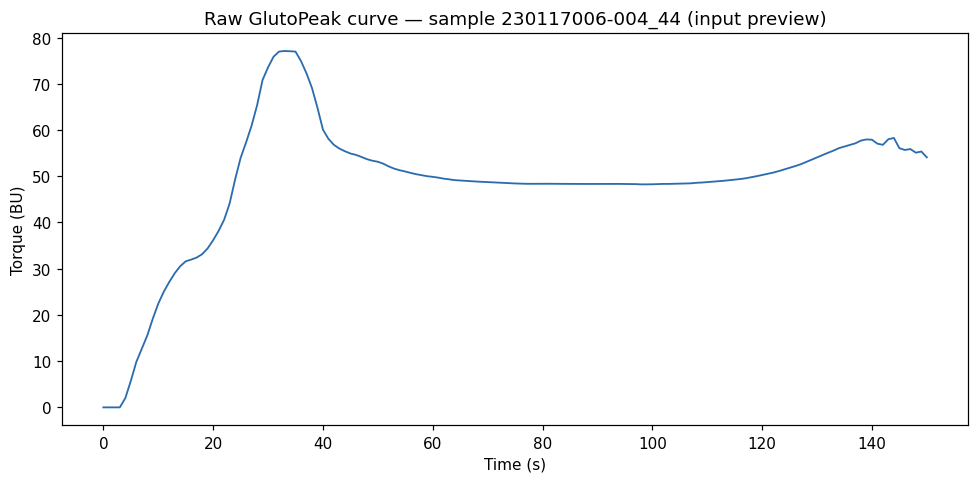

In [ ]:
import datetime, openpyxl, matplotlib.pyplot as plt

XLSX = "/content/gp_rf/sample/230117006-004_44.xlsx"
wb = openpyxl.load_workbook(XLSX, read_only=True, data_only=True)
ws = wb["Measurement"]
it = ws.iter_rows(values_only=True)
header = list(next(it))
i_time, i_tq = header.index("Time[mm:ss]"), header.index("TorqueMean[BU]")

def to_sec_author(t):
    # author semantics: minute(ymd_hms(Time))*60 + second(ymd_hms(Time))
    if isinstance(t, datetime.datetime):
        if t.hour != 0:
            print(f"note: nonzero hour part in time column at {t}")
        return t.minute * 60 + t.second
    parts = str(t).split(":")
    if len(parts) == 3:
        return int(parts[1]) * 60 + int(parts[2])
    return int(parts[0]) * 60 + int(parts[1])

curve = sorted((to_sec_author(r[i_time]), r[i_tq]) for r in it
               if r[i_time] is not None and r[i_tq] is not None)
curve = [(t, q) for t, q in curve if t < 151]  # author filter: time < 151 s
times, torque = zip(*curve)
print(f"points: {len(times)}, time span {times[0]}..{times[-1]} s")

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=110)
ax.plot(times, torque, lw=1.2, color="#2b6cb0")
ax.set_xlabel("Time (s)"); ax.set_ylabel("Torque (BU)")
ax.set_title("Raw GlutoPeak curve — sample 230117006-004_44 (input preview)")
fig.tight_layout()
fig.savefig("/content/gp_rf/input_curve.png")
plt.show()

### 5.1 Run the authors' verbatim feature computation + prediction in R

This cell writes an R script to `/content/gp_rf/` and executes it with `Rscript` (checked subprocess, finite timeout). Inside the script:

- **Verbatim** from `Apply prediction models.R` (commit `e3e3894`): the whole per-file block — `Measurement` sheet reading, `time < 151` filter, sliding-window columns (`slide_mean`/`slide_max` windows 15/7/11, `rleid`), the 19 engineered summary statistics (`Max_time` … `torque_decrease`), the PM/AM slope fallbacks (including the `First_peak_time + 15 ≥ 151` → 150 s handling of the author's lines 47–51), the pivot-wide + column cleanup, and `sample` naming.
- **AI adaptations (labeled in-script):** (1) the time conversion uses lubridate `minute()`/`second()` directly on the `readxl` POSIXct column — on this runtime `ymd_hms()` failed to parse the zero-time row `1899-12-31 00:00:00 UTC`; the computed quantity `minute*60+second` is exactly the author's (the hour part is 0 for all rows here and the author's `ymd_hms` route also ignored hours); (2) the working directory points to the Colab sample folder (the author hardcoded a Windows path); (3) one extra labeled block stashes the time series for plotting; (4) the prediction section enumerates the loaded model objects and predicts with every documented no-protein model (the author's script hard-codes `Absorption_RF_no_protein` at line 100; the exact object names inside the `.RData` are unobserved metadata, so they are listed at runtime instead of guessed). Grain protein is not available in the dataset, which is precisely the situation the author's script documents for the `_no_protein` models ("accuracies… marginally lower, but very close").

**日本語:** 著者のRコードの特徴量計算部をそのまま実行します。変更点(パス、プロット用の時系列保存、no_proteinモデルの列挙)はスクリプト内に明記してあります。

In [ ]:
R_SCRIPT = r'''# Feature computation copied VERBATIM from
# jhprice/Predicting_Farino_from_GP_RF @ e3e3894, "Code from publication/Apply prediction models.R" lines 19-89.
# AI adaptations (documented in the notebook): wd path, time-series stash for plotting (labeled),
# prediction glue enumerating no_protein models instead of hard-coded Absorption_RF_no_protein.
suppressPackageStartupMessages({
  library(tidyverse); library(slider); library(readxl)
  library(lubridate); library(data.table)
})
wd <- "/content/gp_rf/sample/"
files <- list.files(wd)
stopifnot(length(files) == 1)
complete_out <- data.frame()

for(i in files){
  data <- read_xlsx(paste0(wd,i), sheet = "Measurement")
  # AI adaptation (documented in the notebook): on this runtime readxl returns the
  # Time column as POSIXct (1899-12-31 00:00:xx UTC); ymd_hms() failed to parse the
  # zero-time row. minute()/second() are applied to the POSIXct directly - the same
  # author quantity minute*60+second (the author's ymd_hms route also ignored hours).
  data <- data %>% mutate(time = (minute(data$`Time[mm:ss]`) * 60 + second(data$`Time[mm:ss]`)))
  data <- data %>% filter(time < 151)
  data <- data %>% mutate(slide_torque_av = slide_mean(`TorqueMean[BU]`, before = 7, after = 7))
  data <- data %>% mutate(slide_forward = slide_mean(`TorqueMean[BU]`, before = 0, after = 7))
  data <- data %>% mutate(dif = `TorqueMean[BU]` -slide_torque_av)
  data <- data %>% mutate(dif_forward = `TorqueMean[BU]` -slide_forward)
  data <- data %>% mutate(slide_torque_max = slide_max(`TorqueMean[BU]`, before = 5, after = 5))
  data <- data %>% mutate(rl = rleid(dif > 0))
  data <-data %>% mutate(trap = slide_mean(`Torque[BU]`, after = 1, before = 0))
  summary <-data.frame(0)
  summary$Max_time <- data %>% filter(`TorqueMean[BU]` == max(`TorqueMean[BU]`)) %>% select(time) %>% as.numeric()
  summary$Max_torque <- max(data$`TorqueMean[BU]`)
  summary$Max_dif <- data %>% filter(dif == max(dif)) %>% select(dif) %>% as.numeric()
  summary$Max_dif_time <- data %>% filter(dif == max(dif)) %>% select(time) %>% as.numeric()
  summary$First_peak_time <- data %>% filter(slide_torque_max*.95 <= `TorqueMean[BU]`) %>% filter(dif_forward > `TorqueMean[BU]`*.025) %>% filter(time == min(time)) %>% select(time) %>% as.numeric()
  summary$First_peak_torque <- data %>% filter(slide_torque_max*.95 <= `TorqueMean[BU]`) %>% filter(dif_forward > `TorqueMean[BU]`*.025) %>% filter(time == min(time)) %>% select(`TorqueMean[BU]`) %>% as.numeric()
  summary$Max_before60_torque <- data %>% filter(time < 60) %>% summarise(max(`TorqueMean[BU]`)) %>% as.numeric()
  if(summary$First_peak_time + 15 < 151){
  PM <- data %>% filter(time == summary$First_peak_time + 15) %>% select(`TorqueMean[BU]`) %>% as.numeric()
  summary$PMslope <- (summary$First_peak_torque - PM)/15}else{
      PM <- data %>% filter(time == 150) %>% select(`TorqueMean[BU]`) %>% as.numeric()
      summary$PMslope <- (summary$First_peak_torque - PM)/(150 - summary$First_peak_time)}
  if(summary$First_peak_time - 15 > 1){
    AM <- data %>% filter(time == summary$First_peak_time - 15) %>% select(`TorqueMean[BU]`) %>% as.numeric()
    summary$AMslope <- (summary$First_peak_torque - AM)/15}else{
      AM <- data %>% filter(time == 0) %>% select(`TorqueMean[BU]`) %>% as.numeric()
      summary$AMslope <- (summary$First_peak_torque - AM)/summary$First_peak_time}
  firstpeak_rel <- data %>% filter(time == summary$First_peak_time) %>% select(rl)
  maxpeakrl <- data %>% filter(time == summary$Max_time) %>% select(rl)
  summary$firstpeakarea <- data %>% filter(rl == firstpeak_rel$rl) %>% summarise(sum(trap)) %>% as.numeric()
  summary$maxpeakarea <- data %>% filter(rl == maxpeakrl$rl) %>% summarise(sum(trap)) %>% as.numeric()
  summary$time_near_max <- data %>% filter(`TorqueMean[BU]` > max(`TorqueMean[BU]`) *.80) %>% count() %>% as.numeric()
  summary$trough_time <- data %>% filter(time > summary$First_peak_time) %>% filter(`TorqueMean[BU]` == min(`TorqueMean[BU]`)) %>% filter(time==max(time)) %>% select(time) %>% as.numeric()
  summary$trough_torque <- data %>% filter(time > summary$First_peak_time) %>% filter(`TorqueMean[BU]` == min(`TorqueMean[BU]`)) %>% filter(time==max(time)) %>% select(`TorqueMean[BU]`) %>% as.numeric()
  summary$peak_slope <- as.numeric((summary$First_peak_torque-summary$trough_torque)/(summary$First_peak_time - summary$trough_time))
  summary$A12 <- data %>% filter(time >= summary$First_peak_time & time <= summary$trough_time) %>% summarise(sum(trap)) %>% as.numeric()
  summary$A01 <- data %>% filter(time <= summary$First_peak_time) %>% summarise(sum(trap)) %>% as.numeric()
  summary$Torque_at_150 <- data %>% filter(time == max(time)) %>% select(`TorqueMean[BU]`) %>% as.numeric()
  summary$torque_decrease <- summary$First_peak_torque - summary$Torque_at_150
  # --- AI addition (plotting only): stash the curve with computed feature markers ---
  ts_plot <- data %>% transmute(time, torque = `TorqueMean[BU]`,
                                first_peak_time = summary$First_peak_time,
                                first_peak_torque = summary$First_peak_torque,
                                trough_time = summary$trough_time,
                                trough_torque = summary$trough_torque,
                                max_time = summary$Max_time,
                                max_torque = summary$Max_torque)
  write.csv(ts_plot, "/content/gp_rf/ts_plot.csv", row.names = FALSE)
  # --- end AI addition ---
  data <- data %>% select(time, dif,`TorqueMean[BU]`) %>% pivot_wider(names_from = time, values_from = c(dif, `TorqueMean[BU]`), names_prefix = "sec")
  data <- cbind(data, summary[-c(1)])
  colnames(data) <-gsub("`","",colnames(data))
  data$sample <- paste0(sub("\\.xlsx$", "", i)) %>% as.character()
  complete_out <- bind_rows(complete_out, data)
}
complete_out <- complete_out %>% select(!starts_with("dif")) %>% select(!starts_with("TorqueMean[BU]"))

# ==== AI glue: enumerate loaded models; predict with documented no-protein models ====
env_main <- new.env(); load("/content/gp_rf/Random_forest_models_Glutopeak_farinograph.RData", envir = env_main)
env_np   <- new.env(); load("/content/gp_rf/Random_forest_modelsno_protein_Glutopeak_farinograph.RData", envir = env_np)
cat("== objects in Random_forest_models_Glutopeak_farinograph.RData ==\n"); print(ls(env_main))
cat("== objects in Random_forest_modelsno_protein_Glutopeak_farinograph.RData ==\n"); print(ls(env_np))
is_model <- function(n, env) inherits(get(n, envir = env), c("train", "randomForest"))
np_names <- Filter(function(n) is_model(n, env_np), ls(env_np))
if (length(np_names) == 0) {
  np_names <- grep("no_protein", c(ls(env_main), ls(env_np)), value = TRUE)
}
stopifnot(length(np_names) > 0)
pred_rows <- lapply(np_names, function(m) {
  env_of_m <- if (m %in% ls(env_np)) env_np else env_main
  p <- predict(get(m, envir = env_of_m), complete_out)
  data.frame(model = m, sample = complete_out$sample,
             prediction = if (is.factor(p)) as.character(p) else as.numeric(p))
})
pred_df <- do.call(rbind, pred_rows)
write.csv(pred_df, "/content/gp_rf/predictions.csv", row.names = FALSE)
write.csv(complete_out, "/content/gp_rf/features.csv", row.names = FALSE)
cat("== engineered feature row (transposed) ==\n"); print(t(complete_out))
cat("== predictions ==\n"); print(pred_df)
'''
import pathlib, subprocess
pathlib.Path("/content/gp_rf").mkdir(parents=True, exist_ok=True)
pathlib.Path("/content/gp_rf/run_features.R").write_text(R_SCRIPT)
# Output is captured and echoed so the R evidence (model enumeration, feature row,
# predictions) is visible in the saved notebook; the script itself finishes in seconds.
r_ = subprocess.run(["Rscript", "/content/gp_rf/run_features.R"],
                    capture_output=True, text=True, timeout=900)
print(r_.stdout)
if r_.returncode != 0:
    print(r_.stderr)
    r_.check_returncode()

== objects in Random_forest_models_Glutopeak_farinograph.RData ==
[1] "Absorption_RF"     "BakeAbsorption_RF" "MTI_category_RF"  
[4] "MTI_numeric_RF"    "TS_category_RF"    "TS_long_RF"       
[7] "TS_numeric_RF"    
== objects in Random_forest_modelsno_protein_Glutopeak_farinograph.RData ==
[1] "Absorption_RF_no_protein"     "BakeAbsorption_RF_no_protein"
[3] "MTI_category_RF_no_protein"   "MTI_numeric_RF_no_protein"   
[5] "TS_category_RF_no_protein"    "TS_long_RF_no_protein"       
[7] "TS_numeric_RF_no_protein"    
== engineered feature row (transposed) ==
                    [,1]              
Max_time            "33"              
Max_torque          "77.107"          
Max_dif             "7.172067"        
Max_dif_time        "32"              
First_peak_time     "32"              
First_peak_torque   "76.98"           
Max_before60_torque "77.107"          
PMslope             "1.519533"        
AMslope             "2.970933"        
firstpeakarea       "930.038"         
ma

### 5.2 The engineered feature markers on the actual curve

The paper's core idea is to summarize this curve (first peak, trough, areas, slopes) and predict Farinograph traits from those summaries. The plot below is the same actual sample curve with the feature locations computed by the authors' R code (`ts_plot.csv` exported above). (Figure created for this notebook; marker positions come from the author computation, not hand annotation.)

**日本語:** 著者コードが計算した特徴量の位置(第一ピーク・トラフ・最大値)を実際の曲線上に重ねて表示します。

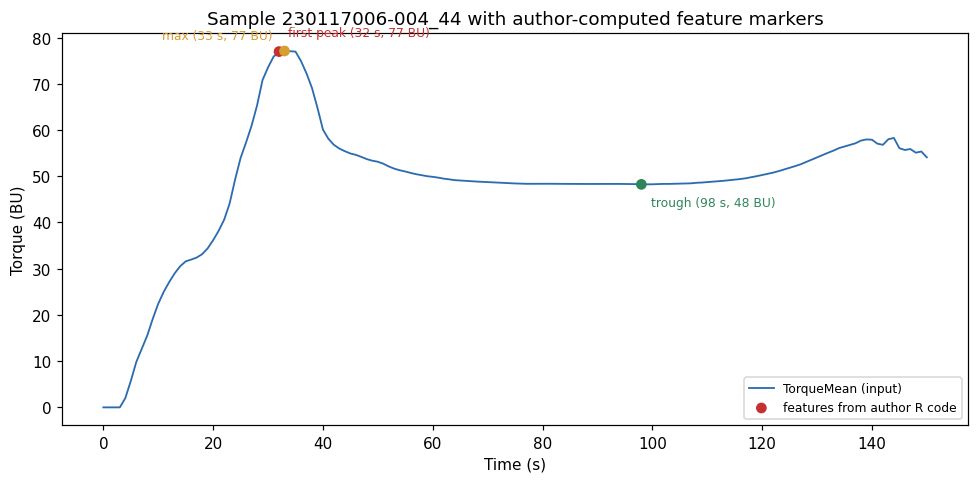

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

ts = pd.read_csv("/content/gp_rf/ts_plot.csv")
row = ts.iloc[0]
fp_t, fp_q = row["first_peak_time"], row["first_peak_torque"]
tr_t, tr_q = row["trough_time"], row["trough_torque"]
mx_t, mx_q = row["max_time"], row["max_torque"]

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=110)
ax.plot(ts["time"], ts["torque"], lw=1.2, color="#2b6cb0", label="TorqueMean (input)")
ax.scatter([fp_t, tr_t, mx_t], [fp_q, tr_q, mx_q],
           color=["#c53030", "#2f855a", "#d69e2e"], zorder=3,
           label="features from author R code")
ax.annotate(f"first peak ({fp_t:.0f} s, {fp_q:.0f} BU)", (fp_t, fp_q),
            textcoords="offset points", xytext=(6, 10), fontsize=8, color="#c53030")
ax.annotate(f"trough ({tr_t:.0f} s, {tr_q:.0f} BU)", (tr_t, tr_q),
            textcoords="offset points", xytext=(6, -14), fontsize=8, color="#2f855a")
ax.annotate(f"max ({mx_t:.0f} s, {mx_q:.0f} BU)", (mx_t, mx_q),
            textcoords="offset points", xytext=(-80, 8), fontsize=8, color="#d69e2e")
ax.set_xlabel("Time (s)"); ax.set_ylabel("Torque (BU)")
ax.set_title("Sample 230117006-004_44 with author-computed feature markers")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig("/content/gp_rf/feature_markers.png")
plt.show()

### 5.3 Predicted Farinograph traits for this sample

Each row is one published model object loaded from the `.RData` files and applied to this sample via the authors' pipeline. Regression targets are continuous Farinograph traits (absorption in %, tolerance stability in minutes, mixing tolerance index in BU — units as defined in the paper); classification models output the industry-guided TS/MTI category labels defined in `Model development.R` (TS: 0 = unacceptable < 7.5, 1 = acceptable 7.5–14, 2 = excellent ≥ 14 min; MTI: 2 = < 20, 1 = 20–40, 0 = ≥ 40 BU). One-sample predictions demonstrate the released pipeline, **not** the paper's cross-validated accuracy.

**日本語:** 各行は `.RData` に保存されたモデルを1つ適用した予測値です。1サンプルの予測は論文の交差検証精度の再現ではありません。分類モデルの出力は業界基準に基づくカテゴリです。

In [ ]:
import pandas as pd

preds = pd.read_csv("/content/gp_rf/predictions.csv")
feats = pd.read_csv("/content/gp_rf/features.csv")
assert preds["sample"].nunique() == 1
display(preds)
print()
print("sample:", preds["sample"].iloc[0],
      "| engineered features used:", feats.shape[1] - 1, "(the author's summary statistics)")
preds.to_csv("/content/gp_rf/predictions_export.csv", index=False)

,model,sample,prediction
0,Absorption_RF_no_protein,230117006-004_44,63.789613
1,BakeAbsorption_RF_no_protein,230117006-004_44,65.555210
2,MTI_category_RF_no_protein,230117006-004_44,0.000000
3,MTI_numeric_RF_no_protein,230117006-004_44,46.437833
4,TS_category_RF_no_protein,230117006-004_44,0.000000
5,TS_long_RF_no_protein,230117006-004_44,0.000000
6,TS_numeric_RF_no_protein,230117006-004_44,5.896777



sample: 230117006-004_44 | engineered features used: 19 (the author's summary statistics)


## 6. Interpretation, differences from the paper, validation record

**What this run shows.** The published no-protein random forest models load from the pinned `.RData` files and produce predictions for one raw GlutoPeak run, using the authors' own feature pipeline (19 engineered summary statistics from the 150 s torque curve). The predicted values and category labels come from the authors' released objects; the marker plot above shows where those features sit on the actual curve.

**Differences and limitations.**
- This is a **partial, one-example demonstration**: the paper's reported accuracy (regression R² 0.488–0.745; classification more accurate than numeric prediction) comes from 5-fold cross-validation over the full population and is **not** re-estimated here.
- Grain protein is unavailable for this dataset file, so the documented **no-protein** models are used (the author's script describes their accuracy as marginally lower but very close to the main models). The protein-using models were therefore not exercised.
- Retraining (`Model development.R`) is out of scope by design; the paper's training setup (caret, `method="rf"`, mtry grid 2–14, 5-fold CV) was read only as provenance.
- The prediction-glue enumerates model object names at runtime instead of hard-coding them (only `Absorption_RF_no_protein` is named in the author's apply script); everything else in the feature pipeline is the authors' code verbatim.

**Validation record.** Executed top-to-bottom in a fresh Colab **CPU** runtime (see notebook outputs for the measured date, package versions and timings). Input bytes verified (git blob SHA-1 for weights; Figshare id/size/ZIP signature for the sample). No GPU is used anywhere.

**日本語:** 本実行は公開済みモデルの適用例(1サンプル)であり、論文の精度の再現ではありません。タンパク質情報がないため、著者が文書化したno-proteinモデルを使用しています。実行は新規のColab CPUランタイムで行われ、入力はハッシュ検証済みです。

## 7. References

- Price, A. J. H., et al. *Random forest regression to predict Farinograph traits from GlutoPeak output in wheat wild relative backcross lines.* Cereal Chemistry 102(3):466–476 (2025). https://doi.org/10.1002/cche.10860
- Author code: https://github.com/jhprice/Predicting_Farino_from_GP_RF (commit `e3e3894745242e6efc043bdfd7e3156a4fba5652`, "Code from publication/Apply prediction models.R", "Model development.R")
- Data: Price et al., Ag Data Commons, https://doi.org/10.15482/USDA.ADC/26487862 (CC0 1.0)
- PhenoPaper investigation `p-c1dbd65cefaa5e94267e637bc15d8864-20260930T015751Z-3165414` was used as prior research guidance; all notebook claims were verified against the pinned primary sources above.